In [2]:
from numba import njit

import numpy as np

from hftbacktest import BacktestAsset, HashMapMarketDepthBacktest, Recorder, ALL_ASSETS, LIMIT, GTX
from hftbacktest.stats import LinearAssetRecord

In [2]:
from datetime import datetime, timedelta
import polars as pl

def generate_days():
    """
    生成2025年1月所有天的日期列表，格式为"2025-01-01"
    """
    # 设置起始和结束日期
    start_date = datetime(2025, 1, 1)
    end_date = datetime(2025, 1, 31)
    
    # 生成所有日期
    dates = []
    current_date = start_date
    
    while current_date <= end_date:
        dates.append(current_date.strftime("%Y-%m-%d"))
        current_date += timedelta(days=1)
    
    return dates

# 使用函数
days = generate_days()
print(days)

['2025-01-01', '2025-01-02', '2025-01-03', '2025-01-04', '2025-01-05', '2025-01-06', '2025-01-07', '2025-01-08', '2025-01-09', '2025-01-10', '2025-01-11', '2025-01-12', '2025-01-13', '2025-01-14', '2025-01-15', '2025-01-16', '2025-01-17', '2025-01-18', '2025-01-19', '2025-01-20', '2025-01-21', '2025-01-22', '2025-01-23', '2025-01-24', '2025-01-25', '2025-01-26', '2025-01-27', '2025-01-28', '2025-01-29', '2025-01-30', '2025-01-31']


In [97]:
solusdt = (
    BacktestAsset()
        .data([f'/mnt/h/data/crypto/tardis_futures_hft_npz/trades_quotes/binance-futures_trades_quotes_{day}_SOLUSDT.npz' for day in days])
        .linear_asset(1.0) 
        .constant_latency(10_000_000, 10_000_000) 
        .risk_adverse_queue_model() 
        .no_partial_fill_exchange()
        .trading_value_fee_model(0.0002, 0.0007)
        .tick_size(0.01)
        .lot_size(0.001)
)

bnbusdt = (
    BacktestAsset()
        .data([f'/mnt/h/data/crypto/tardis_futures_hft_npz/trades_quotes/binance-futures_trades_quotes_{day}_BNBUSDT.npz' for day in days])
        .linear_asset(1.0) 
        .constant_latency(10_000_000, 10_000_000) 
        .risk_adverse_queue_model() 
        .no_partial_fill_exchange()
        .trading_value_fee_model(0.0002, 0.0007)
        .tick_size(0.01)
        .lot_size(0.001)
)

/tmp/ipykernel_2606/2224586072.py:5: DeprecationWarning: constant_latency() is deprecated; use constant_order_latency().
  .constant_latency(10_000_000, 10_000_000)
/tmp/ipykernel_2606/2224586072.py:17: DeprecationWarning: constant_latency() is deprecated; use constant_order_latency().
  .constant_latency(10_000_000, 10_000_000)


In [4]:
@njit
def test(hbt, recorder):
    half_spread_tick = 5
    
    while hbt.elapse(10 * 1e9) == 0:
        hbt.clear_inactive_orders(ALL_ASSETS)

        for asset_no in range(2):
            depth = hbt.depth(asset_no)
            tick_size = depth.tick_size
            mid_price = (depth.best_bid + depth.best_ask) / 2.0

            buy_order_id = 10 * asset_no + 1
            sell_order_id = 10 * asset_no + 2
        
            if buy_order_id not in hbt.orders(asset_no):
                order_price = round((mid_price - half_spread_tick * tick_size) / tick_size) * tick_size
                order_qty = 1
                time_in_force = GTX
                order_type = LIMIT
                hbt.submit_buy_order(asset_no, buy_order_id, order_price, order_qty, time_in_force, order_type, False)
            else:
                hbt.cancel(asset_no, buy_order_id, False)
                
            if sell_order_id not in hbt.orders(asset_no):
                order_price = round((mid_price + half_spread_tick * tick_size) / tick_size) * tick_size
                order_qty = 1
                time_in_force = GTX
                order_type = LIMIT
                hbt.submit_sell_order(asset_no, sell_order_id, order_price, order_qty, time_in_force, order_type, False)
            else:
                hbt.cancel(asset_no, sell_order_id, False)
            
        recorder.record(hbt)

In [100]:
from hftbacktest import LIMIT, GTC, NONE, NEW, FILLED
from numba.typed import List
from numba.types import Tuple, float64

@njit
def test_lead_lag(hbt, recorder, out):
    last_lead_mid_price = None
    lead_diff = 0.0
    cnt = 0    
    while hbt.elapse(1000 * 1e6) == 0: # 100ms  
        is_sumbit = False
        # if cnt == 1000000:
        #     break
        cnt += 1
        hbt.clear_inactive_orders(ALL_ASSETS)
        
        depth_sol = hbt.depth(0)
        mid_price_sol = (depth_sol.best_bid + depth_sol.best_ask) / 2.0
        depth_bnb = hbt.depth(1)
        mid_price_bnb = (depth_bnb.best_bid + depth_bnb.best_ask) / 2.0

        if last_lead_mid_price is None:
            last_lead_mid_price = mid_price_sol
        else:
            lead_diff = (mid_price_sol - last_lead_mid_price) / last_lead_mid_price
            last_lead_mid_price = mid_price_sol

        # order_values = orders.values()
        # exec_value = 0
        # while order_values.has_next():
        #     order = order_values.next()
        #     if order.status == NEW:
        #         exec_value += order.exec_price * order.exec_qty
        # print('exec_value:', exec_value)

        if lead_diff > 0.002:
            cur_position = hbt.position(1)
            # print('pos cur position:', cur_position)
            if cur_position < 0:          
                hbt.submit_buy_order(1, cnt, depth_bnb.best_ask, -cur_position+1, 0, 1, True) # 平空单
                is_sumbit = True
            elif cur_position > 0:
                pass
            else:
                hbt.submit_buy_order(1, cnt, depth_bnb.best_ask, 1, 0, 1, True) # 开多单
                is_sumbit = True
            # if is_sumbit:
            #     print('开多单了')
            #     orders = hbt.orders(1)
            #     print('order exists: ', len(orders))
            #     # print('order status: ', orders.values().next().status)
            #     print('position: ', hbt.position(1))
            #     print('balance: ', hbt.state_values(1).balance)

        if lead_diff < -0.002:
            cur_position = hbt.position(1)            
            if cur_position > 0:
                hbt.submit_sell_order(1, cnt, depth_bnb.best_bid, cur_position+1, 0, 1, True) # 平多单   
                is_sumbit = True        
            elif cur_position < 0:
                pass
            else:
                hbt.submit_sell_order(1, cnt, depth_bnb.best_bid, -1, 0, 1, True) # 开空单
                is_sumbit = True
            # if is_sumbit:
            #     print('开空单了')
            #     orders = hbt.orders(1)
            #     print('order exists: ', len(orders)) 
            #     # print('order status: ', orders.values().next().status)
            #     print('position: ', hbt.position(1))   
            #     print('balance: ', hbt.state_values(1).balance)             
        
        # print("best_bid:", depth_bnb.best_bid, "best_ask:", depth_bnb.best_ask)
        # print("Mid Price:", mid_price_bnb)
        out.append((hbt.current_timestamp, lead_diff, mid_price_sol, mid_price_bnb))
        recorder.record(hbt)

In [101]:
recorder = Recorder(2, 5_000_000)

hbt = HashMapMarketDepthBacktest([solusdt, bnbusdt])

tup_ty = Tuple((float64, float64, float64, float64))
out = List.empty_list(tup_ty, allocated=100_000)

test_lead_lag(hbt, recorder.recorder, out)

_ = hbt.close()

In [102]:
stats = LinearAssetRecord(recorder.get(1)).stats(book_size=10_000)
stats.summary()

start,end,SR,Sortino,Return,MaxDrawdown,DailyNumberOfTrades,DailyTurnover,ReturnOverMDD,ReturnOverTrade,MaxPositionValue
datetime[μs],datetime[μs],f64,f64,f64,f64,f64,f64,f64,f64,f64
2025-01-01 00:00:00,2025-01-31 23:59:50,-10.662261,-14.48786,-0.033314,0.039347,13.354889,1.847024,-0.846674,-0.000582,745.905


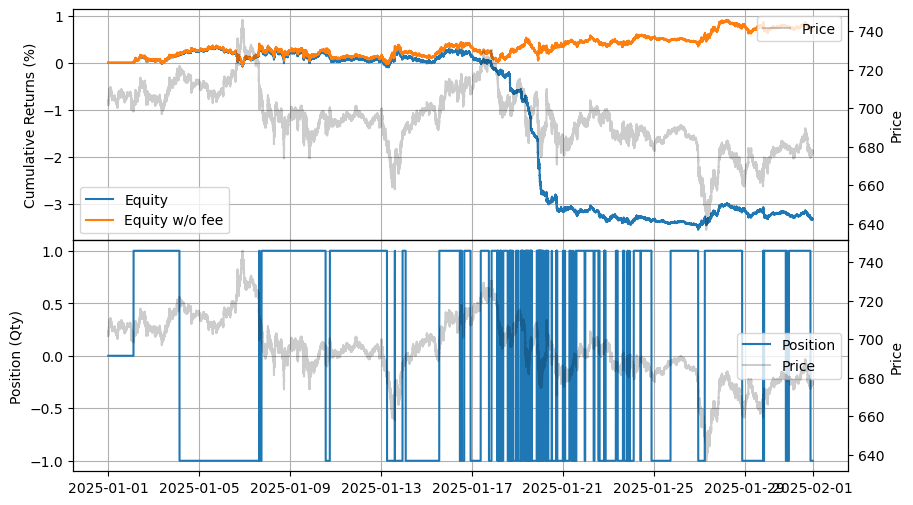

In [103]:
stats.plot()

In [93]:
import polars as pl

df = pl.DataFrame(out).transpose()
df.columns = ['Local Timestamp', 'lead diff', 'mid_price_sol', 'mid_price_bnb']
df = df.with_columns(
    pl.from_epoch('Local Timestamp', time_unit='ns')
)


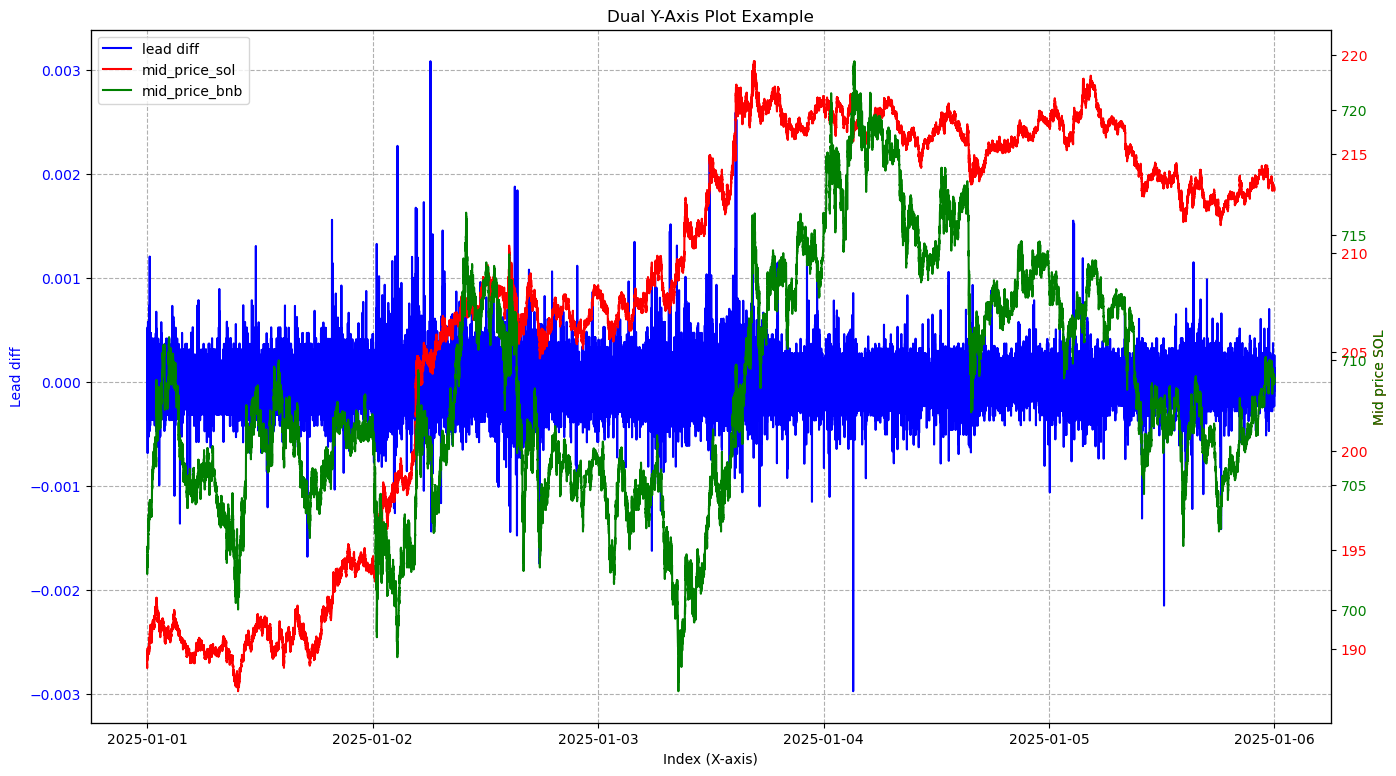

In [94]:
from matplotlib import pyplot as plt

fig, ax1 = plt.subplots(figsize=(16, 9))

line1, = ax1.plot(df['Local Timestamp'], df['lead diff'], color='blue', label='lead diff')

ax1.set_xlabel('Index (X-axis)')
ax1.set_ylabel('Lead diff', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')

ax2 = ax1.twinx()
line2, = ax2.plot(df['Local Timestamp'], df['mid_price_sol'], color='red', label='mid_price_sol')
ax2.set_ylabel('Mid price SOL', color='red')
ax2.tick_params(axis='y', labelcolor='red')
# ax2.set_ylim(180, 200)

ax3 = ax1.twinx()
line3, = ax3.plot(df['Local Timestamp'], df['mid_price_bnb'], color='green', label='mid_price_bnb')
ax3.set_ylabel('Mid price SOL', color='green')
ax3.tick_params(axis='y', labelcolor='green')
# ax3.set_ylim(700, 720)

# 7. 添加图例 (合并两条线的标签)
lines = [line1, line2, line3]
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left')

# 8. 标题和网格
plt.title('Dual Y-Axis Plot Example')
ax1.grid(True, linestyle='--')

# 9. 显示图表
plt.show()

In [6]:
import numpy as np 

# np.load('/mnt/h/data/crypto/tardis_futures_hft_npz/trades_quotes/binance-futures_trades_quotes_2025-01-01_SOLUSDT.npz')['data'][2680:2710]
np.load('/mnt/h/data/crypto/tardis_futures_hft_npz/trades_quotes/binance-futures_trades_quotes_2025-01-01_SOLUSDT.npz')['data'][:20]

array([(3489660929, 1735689600082000000, 1735689601041573000, 189.23, 144., 0, 0, 0.),
       (3758096385, 1735689600082000000, 1735689601041573000, 189.22, 242., 0, 0, 0.),
       (3489660930, 1735689605077000000, 1735689605080898000, 189.22,  37., 0, 0, 0.),
       (3489660930, 1735689605077000000, 1735689605080899000, 189.22,  37., 0, 0, 0.),
       (3489660930, 1735689605077000000, 1735689605080902000, 189.22,   6., 0, 0, 0.),
       (3489660930, 1735689605077000000, 1735689605080905000, 189.22,   9., 0, 0, 0.),
       (3489660930, 1735689605077000000, 1735689605080909000, 189.22,   5., 0, 0, 0.)],
      dtype=[('ev', '<u8'), ('exch_ts', '<i8'), ('local_ts', '<i8'), ('px', '<f8'), ('qty', '<f8'), ('order_id', '<u8'), ('ival', '<i8'), ('fval', '<f8')])

In [ ]:
1735689605089000000 - 1735689600082000000

959573000

In [77]:
pl.read_csv('/mnt/f/data/crypto/tardis_futures/binance-futures_quotes_2025-01-01_SOLUSDT.csv.gz')

exchange,symbol,timestamp,local_timestamp,ask_amount,ask_price,bid_price,bid_amount
str,str,i64,i64,i64,f64,f64,i64
"""binance-futures""","""SOLUSDT""",1735689600082000,1735689601041573,144,189.23,189.22,242
"""binance-futures""","""SOLUSDT""",1735689605089000,1735689605092013,243,189.23,189.22,53
"""binance-futures""","""SOLUSDT""",1735689605140000,1735689605143559,267,189.23,189.22,41
"""binance-futures""","""SOLUSDT""",1735689605192000,1735689605195039,298,189.23,189.22,49
"""binance-futures""","""SOLUSDT""",1735689605245000,1735689605248462,3,189.2,189.19,11
…,…,…,…,…,…,…,…
"""binance-futures""","""SOLUSDT""",1735775999404000,1735775999406632,177,194.23,194.22,421
"""binance-futures""","""SOLUSDT""",1735775999456000,1735775999459411,169,194.23,194.22,198
"""binance-futures""","""SOLUSDT""",1735775999507000,1735775999510846,228,194.23,194.22,170


In [8]:
pl.read_csv('/mnt/f/data/crypto/tardis_futures/binance-futures_trades_2025-01-01_ETHUSDT.csv.gz').sort('timestamp')[:10]

exchange,symbol,timestamp,local_timestamp,id,side,price,amount
str,str,i64,i64,i64,str,f64,f64
"""binance-futures""","""ETHUSDT""",1735689605058000,1735689605061953,4936628773,"""buy""",3336.58,6.583
"""binance-futures""","""ETHUSDT""",1735689605064000,1735689605068158,4936628774,"""sell""",3336.57,0.033
"""binance-futures""","""ETHUSDT""",1735689605072000,1735689605076070,4936628775,"""buy""",3336.58,1.135
"""binance-futures""","""ETHUSDT""",1735689605079000,1735689605081828,4936628776,"""sell""",3336.57,0.46
"""binance-futures""","""ETHUSDT""",1735689605079000,1735689605081836,4936628777,"""sell""",3336.57,0.231
"""binance-futures""","""ETHUSDT""",1735689605079000,1735689605081837,4936628778,"""sell""",3336.57,0.231
"""binance-futures""","""ETHUSDT""",1735689605079000,1735689605081837,4936628779,"""sell""",3336.57,0.784
"""binance-futures""","""ETHUSDT""",1735689605079000,1735689605081837,4936628780,"""sell""",3336.57,0.309
"""binance-futures""","""ETHUSDT""",1735689605079000,1735689605081838,4936628781,"""sell""",3336.57,0.357


In [5]:
pl.read_csv('/mnt/f/data/crypto/tardis_futures/binance-futures_book_snapshot_25_2025-01-01_XRPUSDT.csv.gz').sort('timestamp')

exchange,symbol,timestamp,local_timestamp,asks[0].price,asks[0].amount,bids[0].price,bids[0].amount,asks[1].price,asks[1].amount,bids[1].price,bids[1].amount,asks[2].price,asks[2].amount,bids[2].price,bids[2].amount,asks[3].price,asks[3].amount,bids[3].price,bids[3].amount,asks[4].price,asks[4].amount,bids[4].price,bids[4].amount,asks[5].price,asks[5].amount,bids[5].price,bids[5].amount,asks[6].price,asks[6].amount,bids[6].price,bids[6].amount,asks[7].price,asks[7].amount,bids[7].price,bids[7].amount,asks[8].price,…,bids[15].amount,asks[16].price,asks[16].amount,bids[16].price,bids[16].amount,asks[17].price,asks[17].amount,bids[17].price,bids[17].amount,asks[18].price,asks[18].amount,bids[18].price,bids[18].amount,asks[19].price,asks[19].amount,bids[19].price,bids[19].amount,asks[20].price,asks[20].amount,bids[20].price,bids[20].amount,asks[21].price,asks[21].amount,bids[21].price,bids[21].amount,asks[22].price,asks[22].amount,bids[22].price,bids[22].amount,asks[23].price,asks[23].amount,bids[23].price,bids[23].amount,asks[24].price,asks[24].amount,bids[24].price,bids[24].amount
str,str,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""binance-futures""","""XRPUSDT""",1735689600322000,1735689601680543,2.0836,4536.7,2.0835,7487.9,2.0837,4749.0,2.0834,6065.8,2.0838,13073.4,2.0833,5393.4,2.0839,14307.1,2.0832,13476.9,2.084,22295.9,2.0831,12442.2,2.0841,58302.6,2.083,16451.8,2.0842,7325.8,2.0829,18230.2,2.0843,24336.9,2.0828,21678.1,2.0844,…,39990.0,2.0852,18541.6,2.0819,31104.1,2.0853,32003.7,2.0818,31138.5,2.0854,21594.7,2.0817,9623.6,2.0855,17351.9,2.0816,8277.0,2.0856,30034.9,2.0815,26465.8,2.0857,14197.5,2.0814,19437.9,2.0858,10051.4,2.0813,10627.8,2.0859,12925.8,2.0812,7337.8,2.086,34118.2,2.0811,15620.4
"""binance-futures""","""XRPUSDT""",1735689602083000,1735689602087170,2.0836,4536.7,2.0835,7487.9,2.0837,4749.0,2.0834,6065.8,2.0838,13073.4,2.0833,5393.4,2.0839,14307.1,2.0832,13476.9,2.084,22295.9,2.0831,12442.2,2.0841,58302.6,2.083,16451.8,2.0842,7325.8,2.0829,8610.6,2.0843,24336.9,2.0828,31298.1,2.0844,…,39990.0,2.0852,18541.6,2.0819,31104.1,2.0853,32003.7,2.0818,31138.5,2.0854,21594.7,2.0817,9623.6,2.0855,17351.9,2.0816,8277.0,2.0856,30034.9,2.0815,26465.8,2.0857,14197.5,2.0814,19437.9,2.0858,10051.4,2.0813,10627.8,2.0859,12925.8,2.0812,7337.8,2.086,34118.2,2.0811,15620.4
"""binance-futures""","""XRPUSDT""",1735689602430000,1735689602433269,2.0836,4536.7,2.0835,7487.9,2.0837,4749.0,2.0834,6065.8,2.0838,13073.4,2.0833,5393.4,2.0839,14307.1,2.0832,13476.9,2.084,22295.9,2.0831,12442.2,2.0841,58302.6,2.083,16451.8,2.0842,7325.8,2.0829,8610.6,2.0843,24336.9,2.0828,31298.1,2.0844,…,39990.0,2.0852,18541.6,2.0819,31104.1,2.0853,32003.7,2.0818,31138.5,2.0854,21594.7,2.0817,9623.6,2.0855,17351.9,2.0816,8277.0,2.0856,30034.9,2.0815,26465.8,2.0857,14197.5,2.0814,19437.9,2.0858,10051.4,2.0813,10627.8,2.0859,12925.8,2.0812,7337.8,2.086,34118.2,2.0811,15620.4
"""binance-futures""","""XRPUSDT""",1735689603370000,1735689603374354,2.0836,4536.7,2.0835,7487.9,2.0837,4749.0,2.0834,6065.8,2.0838,13073.4,2.0833,5393.4,2.0839,14307.1,2.0832,13476.9,2.084,22295.9,2.0831,12442.2,2.0841,58302.6,2.083,16451.8,2.0842,7325.8,2.0829,8610.6,2.0843,24336.9,2.0828,31298.1,2.0844,…,39990.0,2.0852,18541.6,2.0819,31104.1,2.0853,32003.7,2.0818,31138.5,2.0854,21594.7,2.0817,9623.6,2.0855,17351.9,2.0816,8277.0,2.0856,30034.9,2.0815,26465.8,2.0857,14197.5,2.0814,19437.9,2.0858,10051.4,2.0813,10627.8,2.0859,12925.8,2.0812,7337.8,2.086,34118.2,2.0811,15620.4
"""binance-futures""","""XRPUSDT""",1735689605092000,1735689605094872,2.0835,1110.8,2.0834,5059.2,2.0836,421.9,2.0833,5393.4,2.0837,4749.0,2.0832,13476.9,2.0838,13073.4,2.0831,5276.2,2.0839,14307.1,2.083,6832.5,2.084,22596.7,2.0829,15825.3,2.0841,58257.6,2.0828,31298.1